# 01 — Visualisation et statistiques des datasets endoscopiques

Ce notebook (Étape C) est prêt pour **« Tout exécuter »** sur Google Colab ou en local :
1. Monte Google Drive (sur Colab) et localise le dépôt `endo-depth`.
2. Charge ton dataset (`c3vd` ou `simcol3d` depuis Drive/local). *Si aucun dataset réel n'est encore téléchargé, crée automatiquement une démo synthétique au format exact C3VD pour tester le pipeline.*
3. Calcule les statistiques (profondeur en mm, pixels valides, reflets spéculaires) et les sauvegarde en JSON.
4. Affiche images RGB, cartes de profondeur, normales de surface et masques de reflets.

In [13]:
import importlib.util
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# === PARAMÈTRES UTILISATEUR ===
REPO_URL = "https://github.com/hanmaZi/endo-depth.git"
DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/endo-depth")
DATASET_NAME = "c3vd"  # "c3vd" ou "simcol3d"
EXPECTED_SEQUENCES = [
    "cecum_t1_a",
    "cecum_t2_a",
    "desc_t4_a",
    "sigmoid_t2_a",
    "sigmoid_t3_a",
    "trans_t1_a",
    "trans_t2_a",
    "trans_t3_a",
    "trans_t3_b",
]  # Mettre [] pour désactiver la vérif stricte
# Choisis ici les séquences à copier/extraire depuis Drive (les séquences déjà extraites dans /content/data/c3vd sont sautées)
SELECTED_SEQUENCES = list(EXPECTED_SEQUENCES)
# Critère anti-fuite de texture : aucune texture (t1/t2/t3/t4) ni couple _a/_b (ex. trans_t3_a, trans_t3_b) ne traverse train/val/test
LOT2_SEQUENCE_SPLITS = {
    "train": ["cecum_t2_a", "sigmoid_t2_a", "sigmoid_t3_a", "trans_t2_a", "trans_t3_a", "trans_t3_b"],
    "val": ["desc_t4_a"],
    "test": ["cecum_t1_a", "trans_t1_a"],
}
IMAGE_SIZE = (256, 256)

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_PROJECT_DIR.mkdir(parents=True, exist_ok=True)
    if Path("/content/endo-depth/.git").is_dir():
        PROJECT_ROOT = Path("/content/endo-depth")
        !git -C {PROJECT_ROOT} pull --ff-only || true
    elif REPO_URL:
        !git clone {REPO_URL} /content/endo-depth
        PROJECT_ROOT = Path("/content/endo-depth")
    elif (DRIVE_PROJECT_DIR / "src").is_dir():
        PROJECT_ROOT = DRIVE_PROJECT_DIR
    else:
        raise RuntimeError(
            "Dépôt endo-depth introuvable sur Colab. Place le dossier dans "
            "MyDrive/endo-depth ou renseigne REPO_URL."
        )
    DATA_BASE = DRIVE_PROJECT_DIR / "data"
    LOCAL_DATA_BASE = Path("/content/data")
    RESULTS_DIR = DRIVE_PROJECT_DIR / "results"
else:
    cwd = Path.cwd()
    PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
    DATA_BASE = PROJECT_ROOT / "data"
    LOCAL_DATA_BASE = PROJECT_ROOT / "data"
    RESULTS_DIR = PROJECT_ROOT / "results"

os.chdir(PROJECT_ROOT)
sys.path = [p for p in sys.path if "drive/MyDrive/endo-depth" not in p]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
for _m in [k for k in sys.modules if k == "src" or k.startswith("src.")]:
    del sys.modules[_m]

missing = [p for p in ["yaml", "cv2"] if importlib.util.find_spec(p) is None]
if missing:
    %pip install -q pyyaml opencv-python-headless

import src.datasets
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("PROJECT_ROOT :", PROJECT_ROOT)
print("src chargé   :", src.datasets.__file__)
print("DATA_BASE    :", DATA_BASE)
print("RESULTS_DIR  :", RESULTS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 7 (delta 6), reused 7 (delta 6), pack-reused 0 (from 0)
Unpacking objects: 100% (7/7), 1.23 KiB | 419.00 KiB/s, done.
From https://github.com/hanmaZi/endo-depth
   7da3426..834cf38  main       -> origin/main
Updating 7da3426..834cf38
Fast-forward
 docs/journal.md      |  4 ++++
 src/datasets/c3vd.py | 27 ++++++++++++++++++++-------
 2 files changed, 24 insertions(+), 7 deletions(-)
PROJECT_ROOT : /content/endo-depth
src chargé   : /content/endo-depth/src/datasets/__init__.py
DATA_BASE    : /content/drive/MyDrive/endo-depth/data
RESULTS_DIR  : /content/drive/MyDrive/endo-depth/results


In [14]:
from src.datasets import (
    C3VDDataset,
    SimCol3DDataset,
    assign_sequence_splits,
    resolve_dataset_dir,
    summarize_records_by_sequence,
)

selected_arg = SELECTED_SEQUENCES if SELECTED_SEQUENCES else None
all_expected_selected = bool(EXPECTED_SEQUENCES) and (
    not SELECTED_SEQUENCES or set(EXPECTED_SEQUENCES).issubset(set(SELECTED_SEQUENCES))
)
expected_for_resolve = EXPECTED_SEQUENCES if all_expected_selected else None

dataset_dir, DATASET_NAME, using_demo = resolve_dataset_dir(
    DATASET_NAME,
    drive_data_base=DATA_BASE,
    local_data_base=LOCAL_DATA_BASE,
    demo_fallback_dir=RESULTS_DIR / "_demo_c3vd",
    expected_sequences=expected_for_resolve,
    selected_sequences=selected_arg,
)
print("Dossier lu par les loaders :", dataset_dir)

expected_arg = None if (using_demo or not expected_for_resolve) else expected_for_resolve
include_arg = None if (using_demo or not selected_arg) else selected_arg
active_splits = None
if (not using_demo) and DATASET_NAME == "c3vd":
    wanted = set(selected_arg) if selected_arg else set(EXPECTED_SEQUENCES)
    lot2_seqs = {s for grp in LOT2_SEQUENCE_SPLITS.values() for s in grp}
    if lot2_seqs.issubset(wanted):
        active_splits = LOT2_SEQUENCE_SPLITS

DatasetCls = C3VDDataset if DATASET_NAME == "c3vd" else SimCol3DDataset
ds_kwargs = (
    {
        "expected_sequences": expected_arg,
        "include_sequences": include_arg,
        "sequence_splits": active_splits,
    }
    if DATASET_NAME == "c3vd"
    else {}
)
full_ds = DatasetCls(dataset_dir, split="all", image_size=IMAGE_SIZE, **ds_kwargs)
train_ds = DatasetCls(dataset_dir, split="train", image_size=IMAGE_SIZE, **ds_kwargs)
val_ds = DatasetCls(dataset_dir, split="val", image_size=IMAGE_SIZE, **ds_kwargs)
test_ds = DatasetCls(dataset_dir, split="test", image_size=IMAGE_SIZE, **ds_kwargs)

frames_per_seq = summarize_records_by_sequence(full_ds.records)
split_sequences = assign_sequence_splits(full_ds.records, sequence_splits=active_splits)
print(f"Dataset chargé ({'DÉMO SYNTHÉTIQUE' if using_demo else 'RÉEL'}) : {DATASET_NAME}")
print("Images par séquence :", frames_per_seq)
print("Découpage par séquence entière :", split_sequences)
print(f"Total frames : {len(full_ds)} | train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}")

[Auto-detect] Dossier(s) C3VD trouvé(s) dans MyDrive : [PosixPath('/content/drive/MyDrive/endo-depth/endo-depth/data/c3vd_zips')]
[Source] /content/drive/MyDrive/endo-depth/endo-depth/data/c3vd_zips contient : ['cecum_t1_a', 'desc_t4_a', 'trans_t1_a']
[Skip] Dossier déjà présent : /content/data/c3vd/cecum_t1_a
[Copy] desc_t4_a/ -> /content/data/c3vd/desc_t4_a
[Copy] trans_t1_a/ -> /content/data/c3vd/trans_t1_a
Dossier lu par les loaders : /content/data/c3vd
[C3VD] Séquences trouvées (total=485 frames) : {'cecum_t1_a': 276, 'desc_t4_a': 148, 'trans_t1_a': 61}
[C3VD] Séquences trouvées (total=485 frames) : {'cecum_t1_a': 276, 'desc_t4_a': 148, 'trans_t1_a': 61}
Dataset chargé (RÉEL) : c3vd
Images par séquence : {'cecum_t1_a': 276, 'desc_t4_a': 148, 'trans_t1_a': 61}
Découpage par séquence entière : {'train': ['cecum_t1_a'], 'val': ['desc_t4_a'], 'test': ['trans_t1_a']}
Total frames : 485 | train=276, val=148, test=61


In [15]:
import json
import numpy as np

max_samples_for_stats = min(len(full_ds), 100)
indices = np.linspace(0, len(full_ds) - 1, max_samples_for_stats, dtype=int)

all_depths = []
valid_ratios = []
specular_ratios = []
has_normals_count = 0

for idx in indices:
    sample = full_ds[int(idx)]
    mask = sample["mask"].squeeze(0).numpy()
    depth = sample["depth"].squeeze(0).numpy()
    spec = sample["specular_mask"].squeeze(0).numpy()

    valid_ratios.append(float(mask.mean()))
    specular_ratios.append(float((spec & mask).sum() / max(1, mask.sum())))
    if sample["has_normals"]:
        has_normals_count += 1
    if mask.any():
        # Échantillonnage pour limiter la RAM sur de gros datasets
        valid_vals = depth[mask]
        step = max(1, len(valid_vals) // 2000)
        all_depths.append(valid_vals[::step])

depth_concat = np.concatenate(all_depths) if all_depths else np.array([0.0])
stats = {
    "dataset": DATASET_NAME,
    "is_synthetic_demo": using_demo,
    "total_frames": len(full_ds),
    "frames_per_sequence": frames_per_seq,
    "split_sequences": split_sequences,
    "splits": {"train": len(train_ds), "val": len(val_ds), "test": len(test_ds)},
    "sampled_frames": int(max_samples_for_stats),
    "has_normals_ratio": round(has_normals_count / max(1, len(indices)), 4),
    "mean_valid_pixel_ratio": round(float(np.mean(valid_ratios)), 4),
    "mean_specular_pixel_ratio": round(float(np.mean(specular_ratios)), 4),
    "depth_mm": {
        "min": round(float(depth_concat.min()), 2),
        "median": round(float(np.median(depth_concat)), 2),
        "mean": round(float(depth_concat.mean()), 2),
        "max": round(float(depth_concat.max()), 2),
        "std": round(float(depth_concat.std()), 2),
    },
}

stats_path = RESULTS_DIR / "dataset_stats.json"
with stats_path.open("w", encoding="utf-8") as f:
    json.dump(stats, f, indent=2, ensure_ascii=False)

print(json.dumps(stats, indent=2, ensure_ascii=False))
print(f"Statistiques sauvegardées dans : {stats_path}")

{
  "dataset": "c3vd",
  "is_synthetic_demo": false,
  "total_frames": 485,
  "frames_per_sequence": {
    "cecum_t1_a": 276,
    "desc_t4_a": 148,
    "trans_t1_a": 61
  },
  "split_sequences": {
    "train": [
      "cecum_t1_a"
    ],
    "val": [
      "desc_t4_a"
    ],
    "test": [
      "trans_t1_a"
    ]
  },
  "splits": {
    "train": 276,
    "val": 148,
    "test": 61
  },
  "sampled_frames": 100,
  "has_normals_ratio": 1.0,
  "mean_valid_pixel_ratio": 0.9271,
  "mean_specular_pixel_ratio": 0.0304,
  "depth_mm": {
    "min": 1.9,
    "median": 24.98,
    "mean": 30.99,
    "max": 99.98,
    "std": 20.97
  }
}
Statistiques sauvegardées dans : /content/drive/MyDrive/endo-depth/results/dataset_stats.json


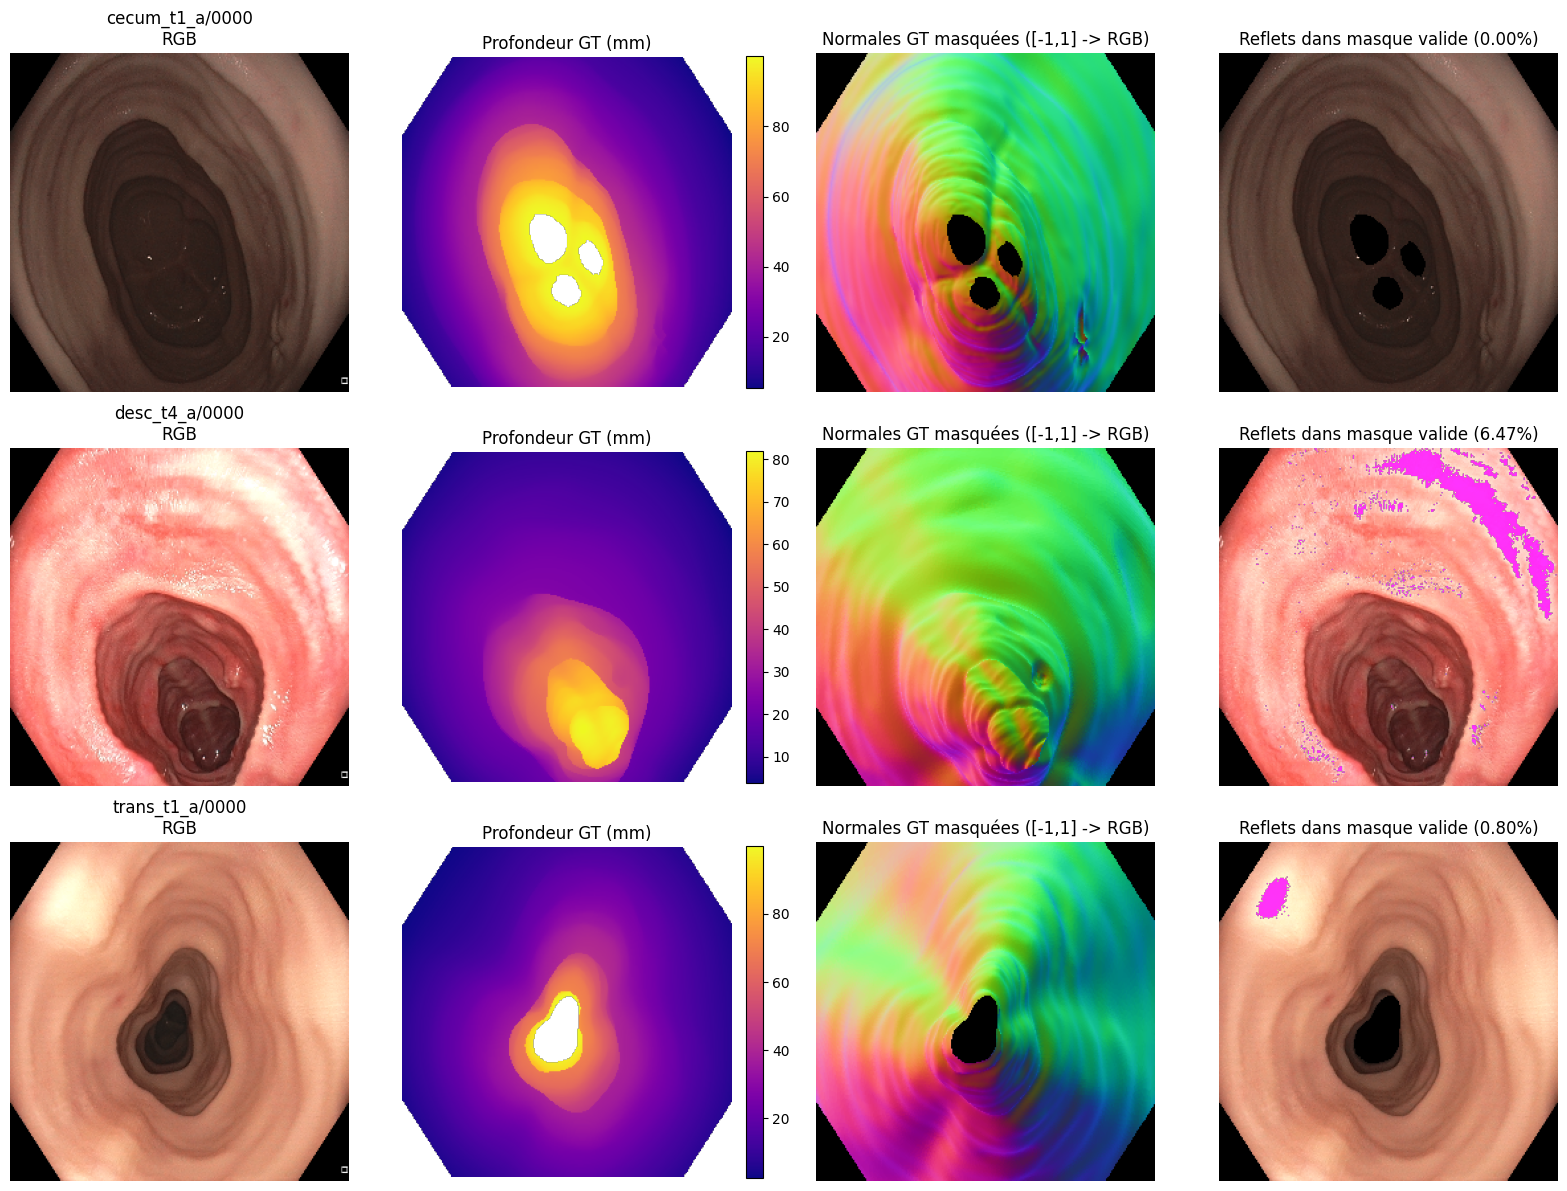

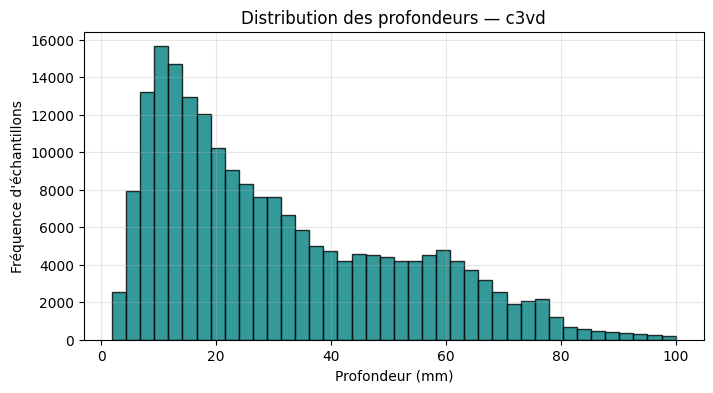

In [16]:
import matplotlib.pyplot as plt

# Affiche 1 image représentative par séquence trouvée (jusqu'à 6 séquences)
first_idx_by_seq = {}
for i, rec in enumerate(full_ds.records):
    if rec.sequence_name not in first_idx_by_seq:
        first_idx_by_seq[rec.sequence_name] = i
show_indices = list(first_idx_by_seq.values())[:9]
num_show = len(show_indices)

fig, axes = plt.subplots(num_show, 4, figsize=(16, 4 * num_show))
if num_show == 1:
    axes = axes[np.newaxis, :]

for row, idx in enumerate(show_indices):
    sample = full_ds[int(idx)]
    rgb = sample["image"].permute(1, 2, 0).numpy()
    depth = sample["depth"].squeeze(0).numpy()
    mask = sample["mask"].squeeze(0).numpy()
    spec = sample["specular_mask"].squeeze(0).numpy()
    normals = sample["normals"].permute(1, 2, 0).numpy()

    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(f"{sample['sequence']}/{sample['frame_id']}\nRGB")
    axes[row, 0].axis("off")

    depth_vis = np.ma.masked_where(~mask, depth)
    im = axes[row, 1].imshow(depth_vis, cmap="plasma")
    axes[row, 1].set_title("Profondeur GT (mm)")
    axes[row, 1].axis("off")
    plt.colorbar(im, ax=axes[row, 1], fraction=0.046, pad=0.04)

    if sample["has_normals"]:
        normals_vis = np.clip((normals + 1.0) * 0.5, 0.0, 1.0)
        normals_vis = np.where(mask[:, :, None], normals_vis, 0.0)
        axes[row, 2].imshow(normals_vis)
        axes[row, 2].set_title("Normales GT masquées ([-1,1] -> RGB)")
    else:
        axes[row, 2].text(0.5, 0.5, "Normales non disponibles", ha="center", va="center")
        axes[row, 2].set_title("Normales")
    axes[row, 2].axis("off")

    spec_valid = spec & mask
    spec_pct = (spec_valid.sum() / max(1, mask.sum())) * 100.0
    rgb_valid_vis = np.where(mask[:, :, None], rgb, 0.0)
    axes[row, 3].imshow(rgb_valid_vis)
    axes[row, 3].imshow(np.ma.masked_where(~spec_valid, spec_valid), cmap="spring", alpha=0.8)
    axes[row, 3].set_title(f"Reflets dans masque valide ({spec_pct:.2f}%)")
    axes[row, 3].axis("off")

plt.tight_layout()
plt.show()

# Histogramme des profondeurs valides
plt.figure(figsize=(8, 4))
plt.hist(depth_concat, bins=40, color="teal", edgecolor="black", alpha=0.8)
plt.xlabel("Profondeur (mm)")
plt.ylabel("Fréquence d'échantillons")
plt.title(f"Distribution des profondeurs — {DATASET_NAME}")
plt.grid(alpha=0.3)
plt.show()